# CSE355 — Image Processing Project

**Workflow:** image setup → grayscale and noise → spatial filtering → frequency filtering → comparison → edge detection → morphology → Otsu thresholding.

The assignment asks for demonstrated algorithmic computation, outputs, and discussion for all four tasks. Run the notebook from top to bottom.

In [86]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import math


## 0. Load the input image

In [87]:
img = cv2.imread('image.jpg')


img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


img = cv2.resize(img, (256, 256), interpolation=cv2.INTER_AREA)


## 1. Convert RGB to grayscale

In [88]:
def rgb_to_grayscale(image):
    height = len(image)
    width = len(image[0])

    grayscale = [
        [0 for _ in range(width)]
        for _ in range(height)
    ]

    for i in range(height):
        for j in range(width):

            R = image[i][j][0]
            G = image[i][j][1]
            B = image[i][j][2]

            gray = 0.299 * R + 0.587 * G + 0.114 * B

            grayscale[i][j] = round(gray)

    return grayscale

## Display helper

In [89]:


def printImg(img):
  # Clip the values to a valid [0, 255] range and cast to uint8
  img_np = np.clip(img, 0, 255).astype(np.uint8)
  plt.imshow(img_np, cmap='gray' if len(img_np.shape) == 2 or img_np.ndim == 2 else None)
  plt.axis('off')
  plt.show()



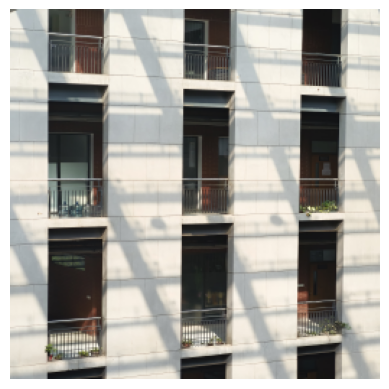

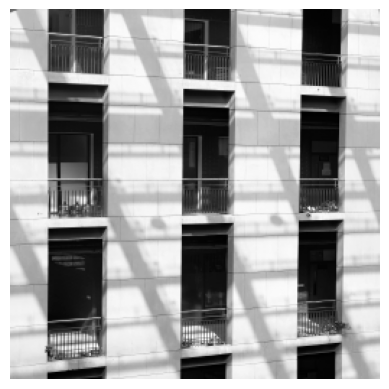

In [90]:
printImg(img)
printImg(rgb_to_grayscale(img))

## 2. Noise-generation functions

In [91]:
def add_gaussian_noise(img, mean=0, sigma=25):
    """
    Add Gaussian noise to a grayscale image (supports both Python lists and NumPy arrays).

    Parameters:
        img   : Grayscale image as a Python list or NumPy array
        mean  : Mean of Gaussian noise
        sigma : Standard deviation of Gaussian noise

    Returns:
        Noisy grayscale image as a NumPy array

    """
    # Ensure the input is a NumPy array
    img_np = np.array(img, dtype=np.float32)

    # Generate Gaussian noise with the same shape as the image
    noise = np.random.normal(mean, sigma, img_np.shape)

    # Add noise
    noisy_img = img_np + noise

    # Keep pixel values in valid range [0, 255]
    noisy_img = np.clip(noisy_img, 0, 255)

    # Convert back to uint8
    return noisy_img.astype(np.uint8)


def add_salt_pepper_noise(img, salt_prob=0.01, pepper_prob=0.01):
    """
    Add salt-and-pepper noise to a grayscale image
    (supports both Python lists and NumPy arrays).

    Parameters:
        img         : Grayscale image as a Python list or NumPy array
        salt_prob   : Probability of salt noise (white pixels, 255)
        pepper_prob : Probability of pepper noise (black pixels, 0)

    Returns:
        Noisy grayscale image as a NumPy array
    """
    # Ensure the input is a NumPy array
    img_np = np.array(img, dtype=np.uint8)

    # Make a copy so the original image is not modified
    noisy_img = img_np.copy()

    # Generate random values for every pixel
    random_values = np.random.random(img_np.shape)

    # Add salt noise (white pixels)
    salt_mask = random_values < salt_prob
    noisy_img[salt_mask] = 255

    # Add pepper noise (black pixels)
    pepper_mask = (
        (random_values >= salt_prob) &
        (random_values < (salt_prob + pepper_prob))
    )
    noisy_img[pepper_mask] = 0

    return noisy_img

### Create the two noisy versions

In [92]:
grayimg = rgb_to_grayscale(img)


# printImg(add_gaussian_noise(grayimg))
# printImg(add_salt_pepper_noise(grayimg, 0.1, 0.1))

grayimgWithSalt = add_salt_pepper_noise(grayimg, 0.1, 0.1)
grayimgWithGaussian = add_gaussian_noise(grayimg, 0, 25)

### View noisy inputs

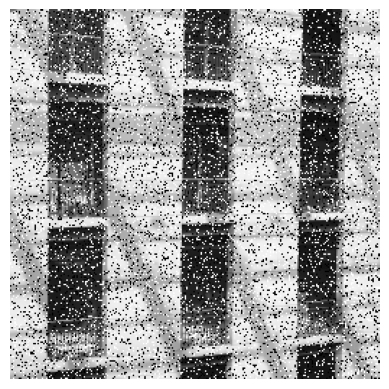

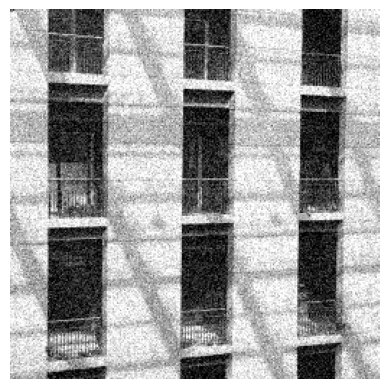

In [93]:
printImg(grayimgWithSalt)
printImg(grayimgWithGaussian)

## 3. Spatial convolution

In [94]:
def convolution2d(image, kernel):
    image_height = len(image)
    image_width = len(image[0])

    kernel_height = len(kernel)
    kernel_width = len(kernel[0])

    # For a 3x3 kernel, padding = 1
    pad_height = kernel_height // 2
    pad_width = kernel_width // 2

    # Create padded image
    padded_height = image_height + 2 * pad_height
    padded_width = image_width + 2 * pad_width

    padded_image = [
        [0 for _ in range(padded_width)]
        for _ in range(padded_height)
    ]

    # Copy original image into the center
    for i in range(image_height):
        for j in range(image_width):
            padded_image[i + pad_height][j + pad_width] = image[i][j]

    # Output image will have same size as input
    output = [
        [0 for _ in range(image_width)]
        for _ in range(image_height)
    ]

    # Convolution
    for i in range(image_height):
        for j in range(image_width):

            total = 0

            for ki in range(kernel_height):
                for kj in range(kernel_width):

                    image_pixel = padded_image[i + ki][j + kj]
                    kernel_value = kernel[ki][kj]

                    total += image_pixel * kernel_value

            output[i][j] = total

    return output

### Kernel notes

### Gaussian-kernel generator

Use `generate_gaussian_kernel()` wherever a Gaussian kernel is needed; avoid manually defining duplicate kernels.

In [95]:

def generate_gaussian_kernel(size=9, sigma=2.0):
    kernel = [[0.0 for _ in range(size)] for _ in range(size)]
    center = size // 2
    sum_val = 0.0

    # Calculate Gaussian values
    for x in range(size):
        for y in range(size):
            dx = x - center
            dy = y - center
            gaussian_val = math.exp(-(dx**2 + dy**2) / (2 * sigma**2))
            kernel[x][y] = gaussian_val
            sum_val += gaussian_val

    # Normalize the kernel so all elements sum to 1.0
    for x in range(size):
        for y in range(size):
            kernel[x][y] /= sum_val

    return kernel

# Generate a 5x5 Gaussian kernel with a larger spread
Gkernel5x5 = generate_gaussian_kernel(size=5, sigma=8)

# Run the 2D convolution with the proper Gaussian kernel
Gres_proper = convolution2d(grayimgWithSalt, Gkernel5x5)

## 4. Frequency-domain helper functions: manual DFT and IDFT

In [96]:


# =====================================================
# MANUAL 2D DFT
# =====================================================

def dft_2d(gray_img):

    M = len(gray_img)
    N = len(gray_img[0])


    # Precompute cosine and sine values

    cos_x = [[0.0 for _ in range(M)] for _ in range(M)]
    sin_x = [[0.0 for _ in range(M)] for _ in range(M)]

    cos_y = [[0.0 for _ in range(N)] for _ in range(N)]
    sin_y = [[0.0 for _ in range(N)] for _ in range(N)]


    for u in range(M):
        for x in range(M):

            angle = -2 * math.pi * u * x / M

            cos_x[u][x] = math.cos(angle)
            sin_x[u][x] = math.sin(angle)



    for v in range(N):
        for y in range(N):

            angle = -2 * math.pi * v * y / N

            cos_y[v][y] = math.cos(angle)
            sin_y[v][y] = math.sin(angle)



    # ------------------------------
    # Row DFT
    # ------------------------------

    temp = [[0j for _ in range(N)] for _ in range(M)]


    for x in range(M):

        for v in range(N):

            real = 0.0
            imag = 0.0


            for y in range(N):

                pixel = gray_img[x][y]

                real += pixel * cos_y[v][y]

                imag += pixel * sin_y[v][y]


            temp[x][v] = complex(real, imag)



    # ------------------------------
    # Column DFT
    # ------------------------------

    spectrum = [[0j for _ in range(N)] for _ in range(M)]


    for u in range(M):

        for v in range(N):

            real = 0.0
            imag = 0.0


            for x in range(M):

                value = temp[x][v]

                a = value.real
                b = value.imag


                c = cos_x[u][x]
                s = sin_x[u][x]


                real += a*c - b*s

                imag += a*s + b*c



            spectrum[u][v] = complex(real, imag)



    return spectrum





# =====================================================
# MANUAL 2D IDFT
# =====================================================


def idft_2d(spectrum):

    M = len(spectrum)
    N = len(spectrum[0])


    # Precompute cosine and sine

    cos_x = [[0.0 for _ in range(M)] for _ in range(M)]
    sin_x = [[0.0 for _ in range(M)] for _ in range(M)]

    cos_y = [[0.0 for _ in range(N)] for _ in range(N)]
    sin_y = [[0.0 for _ in range(N)] for _ in range(N)]



    for x in range(M):

        for u in range(M):

            angle = 2 * math.pi * u*x/M

            cos_x[x][u] = math.cos(angle)

            sin_x[x][u] = math.sin(angle)



    for y in range(N):

        for v in range(N):

            angle = 2 * math.pi * v*y/N

            cos_y[y][v] = math.cos(angle)

            sin_y[y][v] = math.sin(angle)




    # ------------------------------
    # Row IDFT
    # ------------------------------

    temp = [[0j for _ in range(N)] for _ in range(M)]


    for x in range(M):

        for y in range(N):

            real = 0.0
            imag = 0.0



            for v in range(N):

                value = spectrum[x][v]

                a = value.real
                b = value.imag


                c = cos_y[y][v]

                s = sin_y[y][v]


                real += a*c - b*s

                imag += a*s + b*c



            temp[x][y] = complex(real,imag)



    # ------------------------------
    # Column IDFT
    # ------------------------------

    img = [[0.0 for _ in range(N)] for _ in range(M)]



    for x in range(M):

        for y in range(N):

            real = 0.0
            imag = 0.0



            for u in range(M):

                value = temp[u][y]


                a = value.real

                b = value.imag



                c = cos_x[x][u]

                s = sin_x[x][u]



                real += a*c - b*s

                imag += a*s + b*c



            img[x][y] = real/(M*N)



    return img





# =====================================================
# MAGNITUDE SPECTRUM + LOG TRANSFORM
# =====================================================


def magnitude_spectrum(dft_result):

    M = len(dft_result)
    N = len(dft_result[0])


    magnitude = [[0.0 for _ in range(N)] for _ in range(M)]



    for i in range(M):

        for j in range(N):

            real = dft_result[i][j].real

            imag = dft_result[i][j].imag



            value = math.sqrt(real**2 + imag**2)


            # Log transformation

            magnitude[i][j] = math.log(1 + value)



    return magnitude





# =====================================================
# MANUAL FREQUENCY SHIFT
# =====================================================


def manual_shift(matrix):

    M = len(matrix)
    N = len(matrix[0])


    shifted = [[0.0 for _ in range(N)] for _ in range(M)]


    for i in range(M):

        for j in range(N):

            new_i = (i + M//2) % M

            new_j = (j + N//2) % N



            shifted[new_i][new_j] = matrix[i][j]



    return shifted





# =====================================================
# DISPLAY MAGNITUDE SPECTRUM
# =====================================================


def show_magnitude_spectrum(dft_result):


    spectrum = magnitude_spectrum(dft_result)


    spectrum = manual_shift(spectrum)



    plt.figure(figsize=(6,6))


    plt.imshow(
        spectrum,
        cmap="gray"
    )


    plt.title("Magnitude Spectrum")

    plt.axis("off")


    plt.show()

### Gaussian low-pass filter mask

In [97]:


def gaussian_lpf_mask(M, N, D0):

    mask = [[0.0 for _ in range(N)] for _ in range(M)]


    center_x = M // 2
    center_y = N // 2


    for u in range(M):

        for v in range(N):

            # Distance from frequency center

            D = math.sqrt(
                (u-center_x)**2 +
                (v-center_y)**2
            )


            # Gaussian Low Pass Filter equation

            mask[u][v] = math.exp(
                -(D**2)/(2*(D0**2))
            )


    return mask

### Apply the frequency mask

In [98]:
def apply_frequency_filter(dft_result, mask):

    M = len(dft_result)
    N = len(dft_result[0])


    filtered = [
        [0j for _ in range(N)]
        for _ in range(M)
    ]


    for i in range(M):

        for j in range(N):

            filtered[i][j] = (
                dft_result[i][j] *
                mask[i][j]
            )


    return filtered

### Normalize reconstructed image

In [99]:
def normalize_image(image):
    """Normalize an image to the display range [0, 255]."""
    M = len(image)
    N = len(image[0])

    min_val = min(min(row) for row in image)
    max_val = max(max(row) for row in image)

    if max_val == min_val:
        return [[0.0 for _ in range(N)] for _ in range(M)]

    scale = 255.0 / (max_val - min_val)

    return [
        [(pixel - min_val) * scale for pixel in row]
        for row in image
    ]


### Center the spectrum for display/filtering

In [100]:
def shift_complex(matrix):

    M = len(matrix)
    N = len(matrix[0])

    shifted = [
        [0j for _ in range(N)]
        for _ in range(M)
    ]


    for i in range(M):
        for j in range(N):

            new_i = (i + M//2) % M
            new_j = (j + N//2) % N

            shifted[new_i][new_j] = matrix[i][j]


    return shifted

# Task 1A — Spatial-domain denoising

Apply mean and Gaussian filters (3×3 and 5×5) to both noisy images. Compare the results visually.

In [101]:
# Generate the noisy images first
gaussian_noise_img = np.asarray(grayimgWithGaussian, dtype=np.uint8).tolist()  # Gaussian-noise image
sp_noise_img = np.asarray(grayimgWithSalt, dtype=np.uint8).tolist()  # Salt-and-pepper image

mean_3_kernel = np.ones((3,3)) / 9
mean_5_kernel = np.ones((5,5)) / 25

gaussian_3_kernel = generate_gaussian_kernel(
    size=3,
    sigma=1
)

gaussian_5_kernel = generate_gaussian_kernel(
    size=5,
    sigma=1
)

# Mean filter 3x3
gaussian_mean_3 = convolution2d(
    gaussian_noise_img,
    mean_3_kernel
)

# Mean filter 5x5
gaussian_mean_5 = convolution2d(
    gaussian_noise_img,
    mean_5_kernel
)

# Gaussian filter 3x3
gaussian_gaussian_3 = convolution2d(
    gaussian_noise_img,
    gaussian_3_kernel
)

# Gaussian filter 5x5
gaussian_gaussian_5 = convolution2d(
    gaussian_noise_img,
    gaussian_5_kernel
)


# Mean filter on salt-and-pepper noise
sp_mean_3 = convolution2d(
    sp_noise_img,
    mean_3_kernel
)

sp_mean_5 = convolution2d(
    sp_noise_img,
    mean_5_kernel
)

# Gaussian filter on salt-and-pepper noise
sp_gaussian_3 = convolution2d(
    sp_noise_img,
    gaussian_3_kernel
)

sp_gaussian_5 = convolution2d(
    sp_noise_img,
    gaussian_5_kernel
)


### Display spatial-filtering results

In [102]:
def show_results(images, titles):

    plt.figure(figsize=(12,8))


    for i in range(len(images)):

        plt.subplot(2,3,i+1)

        plt.imshow(
            images[i],
            cmap="gray"
        )

        plt.title(titles[i])

        plt.axis("off")


    plt.tight_layout()

    plt.show()

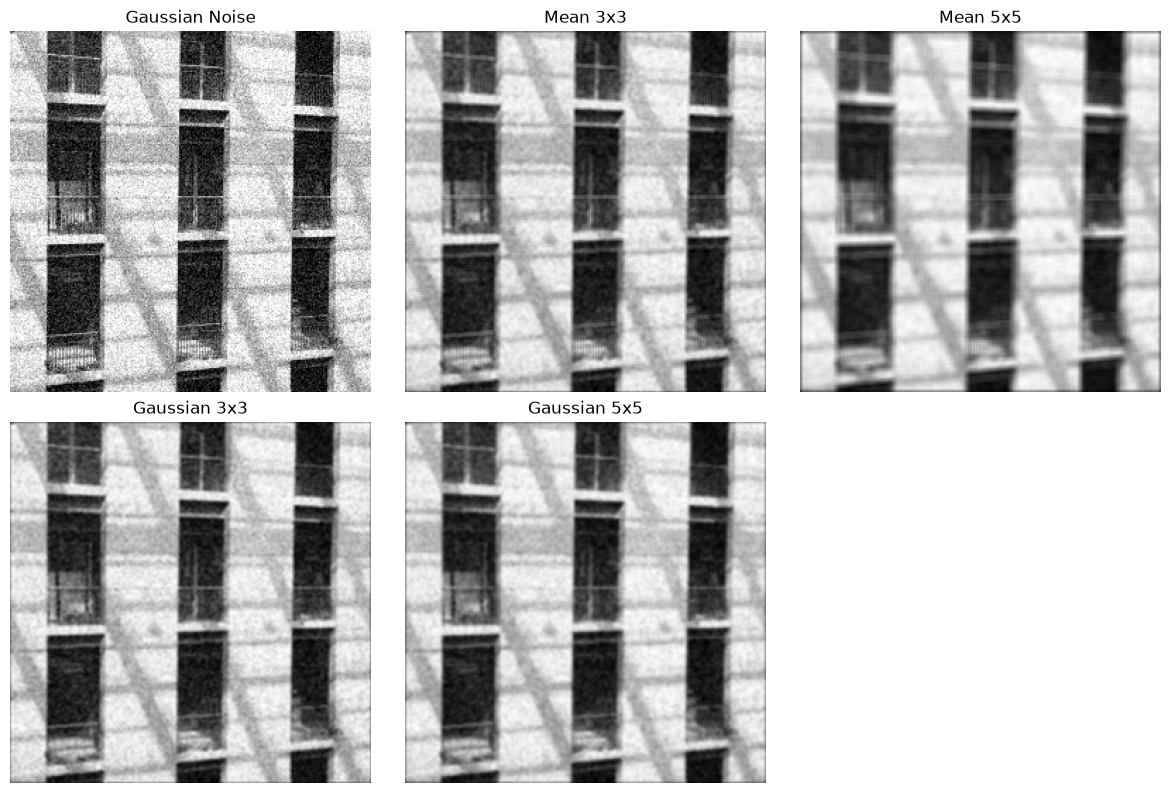

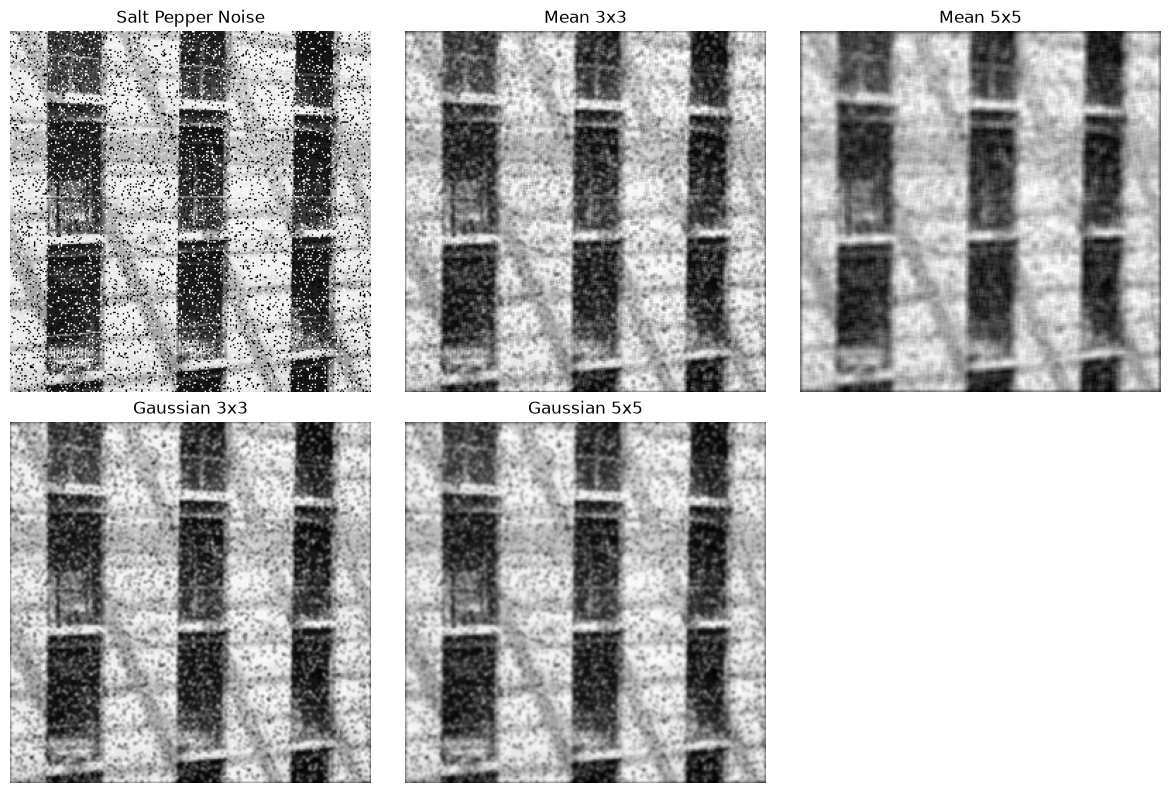

In [103]:
show_results(

[
gaussian_noise_img,
gaussian_mean_3,
gaussian_mean_5,
gaussian_gaussian_3,
gaussian_gaussian_5
],

[
"Gaussian Noise",
"Mean 3x3",
"Mean 5x5",
"Gaussian 3x3",
"Gaussian 5x5"
]

)

show_results(

[
sp_noise_img,
sp_mean_3,
sp_mean_5,
sp_gaussian_3,
sp_gaussian_5
],

[
"Salt Pepper Noise",
"Mean 3x3",
"Mean 5x5",
"Gaussian 3x3",
"Gaussian 5x5"
]

)

# The Ans of 1(B)
# Frequency Domain Performance


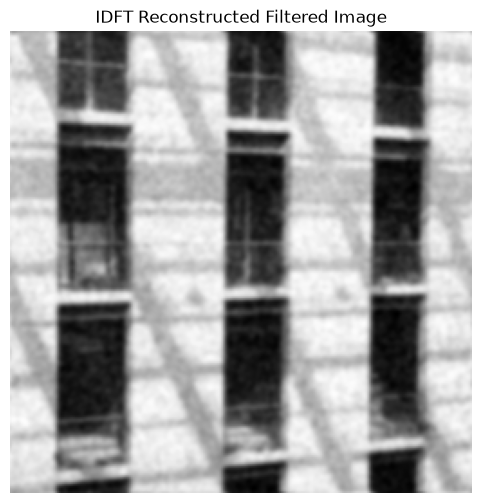

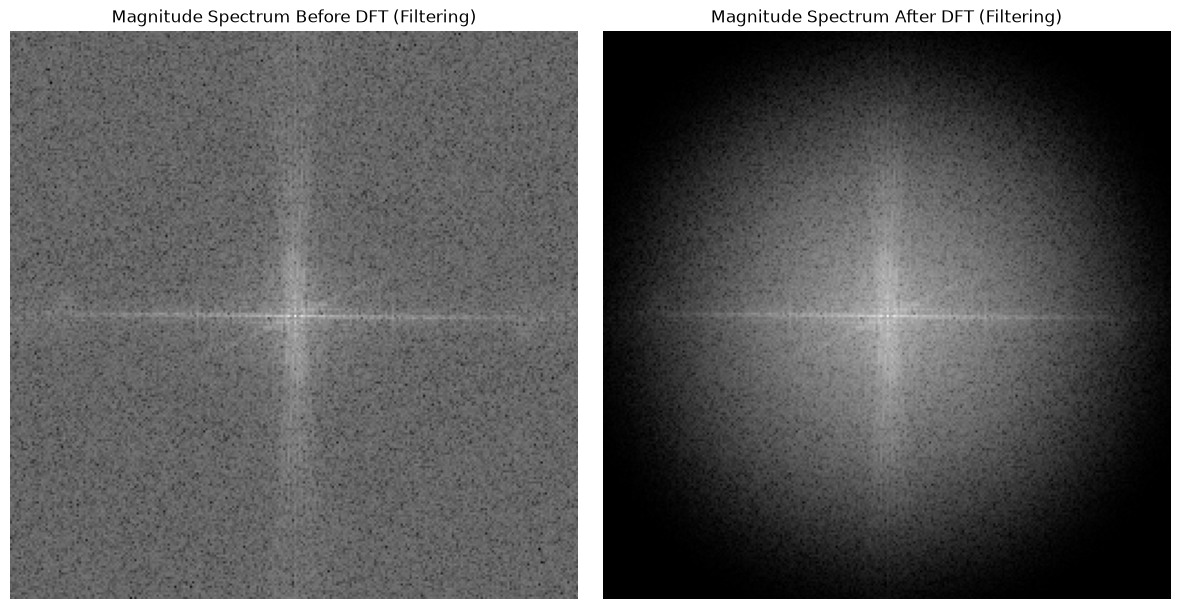

In [104]:

# =====================================
# 1. Compute DFT
# =====================================

dft_before = dft_2d(gaussian_noise_img)



# =====================================
# 2. Apply Gaussian LPF
# =====================================

# Shift DFT
dft_shifted = shift_complex(dft_before)


# Create LPF mask
mask = gaussian_lpf_mask(
    len(dft_shifted),
    len(dft_shifted[0]),
    30
)


# Filtering
dft_after_shifted = apply_frequency_filter(
    dft_shifted,
    mask
)


# Shift back
dft_after = shift_complex(dft_after_shifted)



# =====================================
# 3. IDFT Reconstruction
# =====================================

idft_result = idft_2d(dft_after)


# Preserve the reconstructed intensity scale for a valid MSE/PSNR comparison.
filtered_image = np.clip(
    np.rint(np.asarray(idft_result, dtype=np.float64)),
    0,
    255
).astype(np.uint8)

plt.figure(figsize=(6,6))

plt.imshow(filtered_image,cmap="gray")

plt.title("IDFT Reconstructed Filtered Image")

plt.axis("off")

plt.show()



# =====================================
# 4. Show Frequency Domain Results Side-by-Side
# =====================================

# Compute magnitude spectra and shift them for display
spectrum_before = manual_shift(magnitude_spectrum(dft_before))
spectrum_after = manual_shift(magnitude_spectrum(dft_after))

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(spectrum_before, cmap="gray")
axes[0].set_title("Magnitude Spectrum Before DFT (Filtering)")
axes[0].axis("off")

axes[1].imshow(spectrum_after, cmap="gray")
axes[1].set_title("Magnitude Spectrum After DFT (Filtering)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## Task 1C — Quantitative comparison

### Mean squared error (MSE)

In [105]:
def calculate_mse(original, restored):
    """Calculate mean squared error without uint8 arithmetic overflow."""
    original_np = np.asarray(original, dtype=np.float64)
    restored_np = np.asarray(restored, dtype=np.float64)

    if original_np.shape != restored_np.shape:
        raise ValueError(
            f"Images must have the same shape; got "
            f"{original_np.shape} and {restored_np.shape}."
        )

    return float(np.mean((original_np - restored_np) ** 2))


### Peak signal-to-noise ratio (PSNR)

In [106]:
def calculate_psnr(original, restored):

    mse = calculate_mse(
        original,
        restored
    )


    if mse == 0:
        return float('inf')


    psnr = 10 * math.log10(
        (255**2)/mse
    )


    return psnr

### Compare spatial and frequency results

Use the same original grayscale image as the reference for every metric. Select the best denoised result for Task 2 and state the reason in the report.

In [107]:
print("========== Spatial Domain Comparison ==========")

results = {
    "Mean 3x3": gaussian_mean_3,
    "Mean 5x5": gaussian_mean_5,
    "Gaussian 3x3": gaussian_gaussian_3,
    "Gaussian 5x5": gaussian_gaussian_5
}

psnr_scores = {}

for name, img in results.items():
    mse = calculate_mse(
        grayimg,
        img
    )
    psnr = calculate_psnr(
        grayimg,
        img
    )
    psnr_scores[name] = psnr
    print(
        f"{name}: "
        f"MSE = {mse:.2f}, "
        f"PSNR = {psnr:.2f} dB"
    )

print("\n========== Frequency Domain Comparison ==========")

frequency_mse = calculate_mse(
    grayimg,
    filtered_image
)

frequency_psnr = calculate_psnr(
    grayimg,
    filtered_image
)

print(
    f"Gaussian LPF: "
    f"MSE = {frequency_mse:.2f}, "
    f"PSNR = {frequency_psnr:.2f} dB"
)

# Add frequency result for final selection
psnr_scores["Gaussian LPF"] = frequency_psnr

# Find best result
best_method = max(
    psnr_scores,
    key=psnr_scores.get
)

print("\n========== Best Denoising Method ==========")
print(
    "Best method:",
    best_method
)

if best_method == "Mean 3x3":
    best_denoised = gaussian_mean_3
elif best_method == "Mean 5x5":
    best_denoised = gaussian_mean_5
elif best_method == "Gaussian 3x3":
    best_denoised = gaussian_gaussian_3
elif best_method == "Gaussian 5x5":
    best_denoised = gaussian_gaussian_5
else:
    best_denoised = filtered_image

========== Spatial Domain Comparison ==========
Mean 3x3: MSE = 282.36, PSNR = 23.62 dB
Mean 5x5: MSE = 448.14, PSNR = 21.62 dB
Gaussian 3x3: MSE = 222.61, PSNR = 24.66 dB
Gaussian 5x5: MSE = 240.54, PSNR = 24.32 dB

========== Frequency Domain Comparison ==========
Gaussian LPF: MSE = 251.78, PSNR = 24.12 dB

========== Best Denoising Method ==========
Best method: Gaussian 3x3


# Task 2 — Edge detection

Use the selected denoised image from Task 1. The assignment specifically asks for Canny with two low/high threshold pairs and a discussion of detail changes.

### Prepare the Canny input

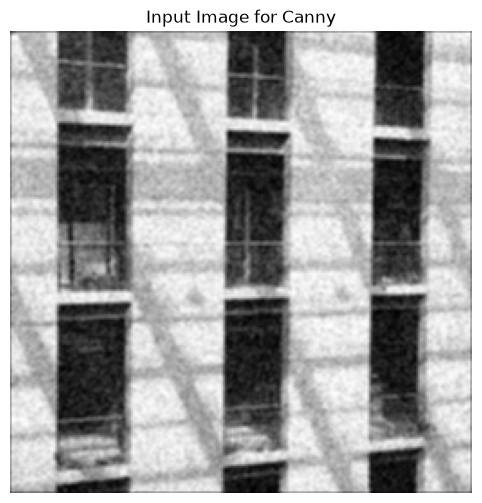

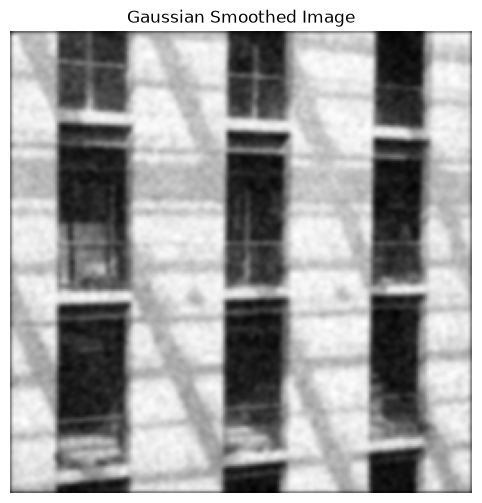

In [108]:
canny_input = best_denoised

gaussian_kernel = generate_gaussian_kernel(
    size=5,
    sigma=1
)


blurred_image = convolution2d(
    canny_input,
    gaussian_kernel
)


plt.figure(figsize=(6,6))

plt.imshow(
    canny_input,
    cmap="gray"
)

plt.title("Input Image for Canny")

plt.axis("off")

plt.show()

plt.figure(figsize=(6,6))

plt.imshow(
    blurred_image,
    cmap="gray"
)

plt.title("Gaussian Smoothed Image")

plt.axis("off")

plt.show()

### Sobel kernels and gradients

In [109]:
sobel_x_kernel = np.array(
[
    [-1,0,1],
    [-2,0,2],
    [-1,0,1]
],
dtype=np.float64
)


sobel_y_kernel = np.array(
[
    [-1,-2,-1],
    [0,0,0],
    [1,2,1]
],
dtype=np.float64
)

### Calculate gradient magnitude and direction

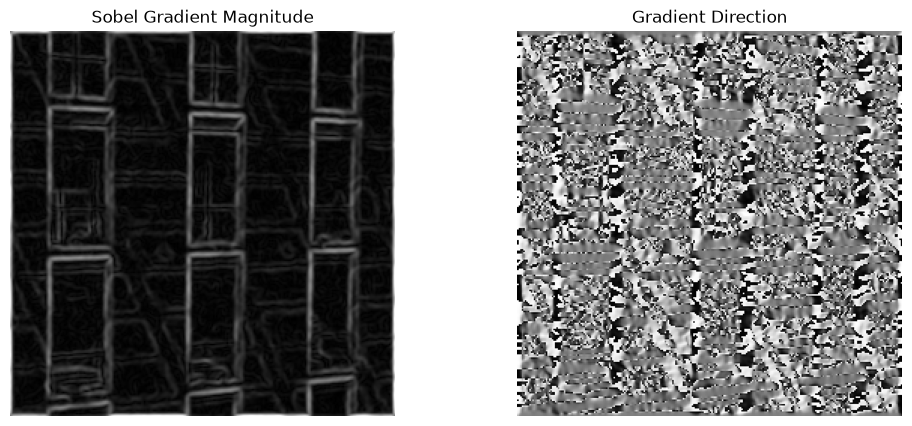

In [110]:
Gx = np.array(
    convolution2d(
        blurred_image,
        sobel_x_kernel
    ),
    dtype=np.float64
)


Gy = np.array(
    convolution2d(
        blurred_image,
        sobel_y_kernel
    ),
    dtype=np.float64
)

gradient_magnitude = np.sqrt(Gx**2 + Gy**2)

gradient_direction = np.arctan2(
    Gy,
    Gx
) * 180 / np.pi


gradient_direction[
    gradient_direction < 0
] += 180



plt.figure(figsize=(12,5))


plt.subplot(1,2,1)

plt.imshow(
    gradient_magnitude,
    cmap="gray"
)

plt.title("Sobel Gradient Magnitude")

plt.axis("off")



plt.subplot(1,2,2)

direction_display = (
    gradient_direction / 180 * 255
).astype(np.uint8)


plt.imshow(
    direction_display,
    cmap="gray"
)

plt.title("Gradient Direction")
plt.axis("off")
plt.show()

## Laplacian Edge Detection


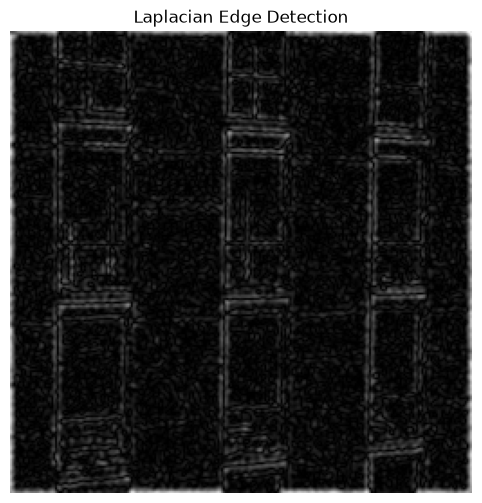

In [111]:
# Laplacian Edge Detection

# 3x3 Laplacian kernel
laplacian_kernel = np.array(
    [
        [0, 1, 0],
        [1, -4, 1],
        [0, 1, 0]
    ],
    dtype=np.float64
)

laplacian_output = np.array(
    convolution2d(
        blurred_image,
        laplacian_kernel
    ),
    dtype=np.float64
)

# Convert the absolute response to a displayable 8-bit image.
laplacian_display = np.uint8(
    np.clip(
        np.abs(laplacian_output),
        0,
        255
    )
)

plt.figure(figsize=(6,6))
plt.imshow(
    laplacian_display,
    cmap="gray"
)
plt.title("Laplacian Edge Detection")
plt.axis("off")
plt.show()


### Canny step 1 — Non-maximum suppression

In [112]:
def non_maximum_suppression(magnitude, direction):

    h, w = magnitude.shape

    suppressed = np.zeros((h, w), dtype=np.float64)


    # Check every pixel except boundary

    for i in range(1, h-1):

        for j in range(1, w-1):

            angle = direction[i,j]


            current = magnitude[i,j]


            # Quantize angle into 4 directions

            # 0 degree
            if (0 <= angle < 22.5) or (157.5 <= angle <= 180):

                neighbor1 = magnitude[i, j+1]
                neighbor2 = magnitude[i, j-1]


            # 45 degree
            elif 22.5 <= angle < 67.5:

                neighbor1 = magnitude[i+1, j-1]
                neighbor2 = magnitude[i-1, j+1]


            # 90 degree
            elif 67.5 <= angle < 112.5:

                neighbor1 = magnitude[i+1, j]
                neighbor2 = magnitude[i-1, j]


            # 135 degree
            else:

                neighbor1 = magnitude[i-1, j-1]
                neighbor2 = magnitude[i+1, j+1]



            # Keep only local maximum

            if current >= neighbor1 and current >= neighbor2:

                suppressed[i,j] = current

            else:

                suppressed[i,j] = 0


    return suppressed

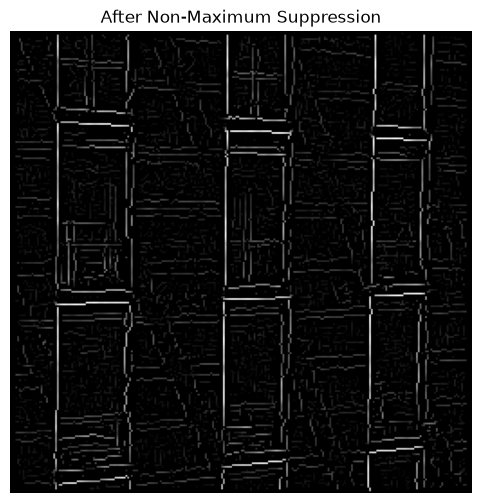

In [113]:
nms_output = non_maximum_suppression(
    gradient_magnitude,
    gradient_direction
)

nms_max = nms_output.max()
nms_display = (
    np.zeros_like(nms_output, dtype=np.uint8)
    if nms_max == 0
    else (nms_output / nms_max * 255).astype(np.uint8)
)



plt.figure(figsize=(6,6))


plt.imshow(
    nms_display,
    cmap="gray"
)


plt.title("After Non-Maximum Suppression")

plt.axis("off")

plt.show()

## Double Threshold Function


In [114]:
def double_threshold(image, low_threshold, high_threshold):

    h, w = image.shape

    output = np.zeros((h,w), dtype=np.uint8)


    strong_value = 255
    weak_value = 50


    for i in range(h):

        for j in range(w):

            pixel = image[i,j]


            if pixel >= high_threshold:

                output[i,j] = strong_value


            elif pixel >= low_threshold:

                output[i,j] = weak_value


            else:

                output[i,j] = 0


    return output

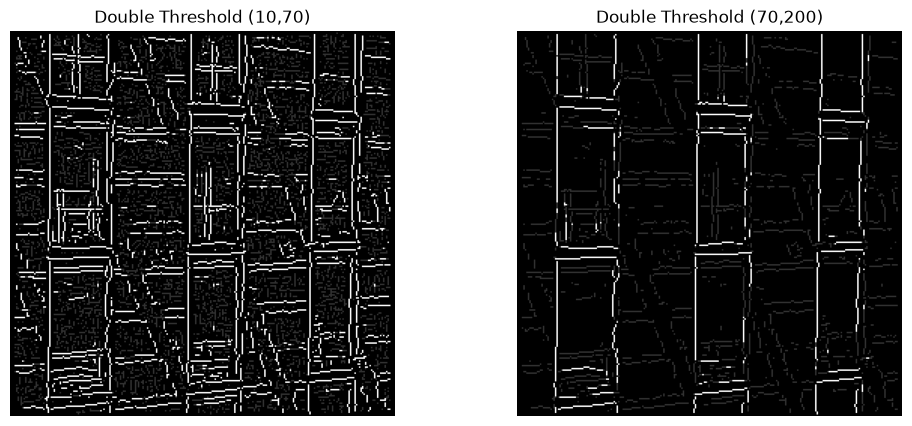

In [115]:
threshold_1 = double_threshold(
    nms_output,
    low_threshold=10,
    high_threshold=70
)

threshold_2 = double_threshold(
    nms_output,
    low_threshold=70,
    high_threshold=200
)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(
    threshold_1,
    cmap="gray"
)
plt.title(
    "Double Threshold (10,70)"
)
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(
    threshold_2,
    cmap="gray"
)
plt.title(
    "Double Threshold (70,200)"
)
plt.axis("off")

plt.show()


### Canny step 3 — Edge tracking by hysteresis

In [116]:
def hysteresis_tracking(threshold_image):
    h, w = threshold_image.shape

    strong = 255
    weak = 50

    # Start with all strong edges.
    output = np.zeros((h, w), dtype=np.uint8)
    output[threshold_image == strong] = strong

    # Iteratively promote weak pixels connected to strong edges.
    # This follows weak-edge chains instead of checking only one neighbour.
    changed = True

    while changed:
        changed = False

        for i in range(1, h - 1):
            for j in range(1, w - 1):

                if threshold_image[i, j] == weak and output[i, j] != strong:

                    neighbourhood = output[i-1:i+2, j-1:j+2]

                    if np.any(neighbourhood == strong):
                        output[i, j] = strong
                        changed = True

    return output


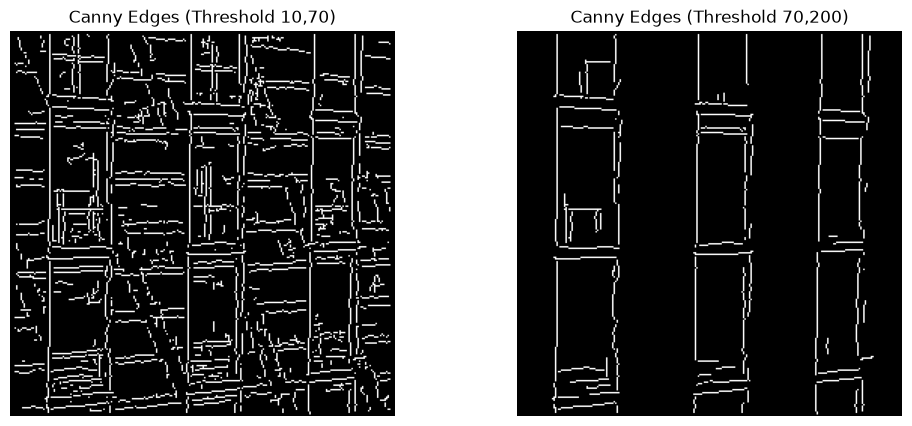

In [117]:
final_edges_1 = hysteresis_tracking(
    threshold_1
)

final_edges_2 = hysteresis_tracking(
    threshold_2
)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(
    final_edges_1,
    cmap="gray"
)
plt.title(
    "Canny Edges (Threshold 10,70)"
)
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(
    final_edges_2,
    cmap="gray"
)
plt.title(
    "Canny Edges (Threshold 70,200)"
)
plt.axis("off")

plt.show()


## Task -3


### Convert Canny output to a clean binary image

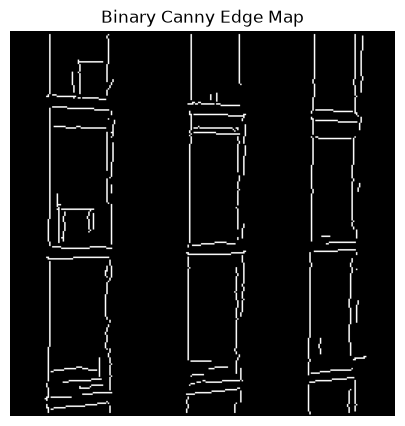

In [118]:
binary_edge_map = np.where(
    final_edges_2 > 0,
    255,
    0
).astype(np.uint8)

plt.figure(figsize=(5,5))

plt.imshow(
    binary_edge_map,
    cmap="gray"
)

plt.title("Binary Canny Edge Map")

plt.axis("off")

plt.show()

### Structuring elements (3×3)

In [119]:
square_kernel = np.ones(
    (3,3),
    dtype=np.uint8
)

cross_kernel = np.array(
[
    [0,1,0],
    [1,1,1],
    [0,1,0]
],
dtype=np.uint8
)

### Erosion implementation

In [120]:
def erosion(binary_image, kernel):

    h,w = binary_image.shape

    k = kernel.shape[0]

    pad = k//2


    padded = np.pad(
        binary_image,
        pad,
        mode="constant",
        constant_values=255
    )


    output = np.zeros(
        (h,w),
        dtype=np.uint8
    )


    for i in range(h):

        for j in range(w):

            region = padded[
                i:i+k,
                j:j+k
            ]


            value = 255


            for x in range(k):

                for y in range(k):

                    if kernel[x,y] == 1:

                        value = min(
                            value,
                            region[x,y]
                        )


            output[i,j] = value


    return output

### Dilation implementation

In [121]:
def dilation(binary_image, kernel):

    h,w = binary_image.shape

    k = kernel.shape[0]

    pad = k//2


    padded = np.pad(
        binary_image,
        pad,
        mode="constant",
        constant_values=0
    )


    output = np.zeros(
        (h,w),
        dtype=np.uint8
    )


    for i in range(h):

        for j in range(w):

            region = padded[
                i:i+k,
                j:j+k
            ]


            value = 0


            for x in range(k):

                for y in range(k):

                    if kernel[x,y] == 1:

                        value = max(
                            value,
                            region[x,y]
                        )


            output[i,j] = value


    return output

### Apply erosion and dilation separately

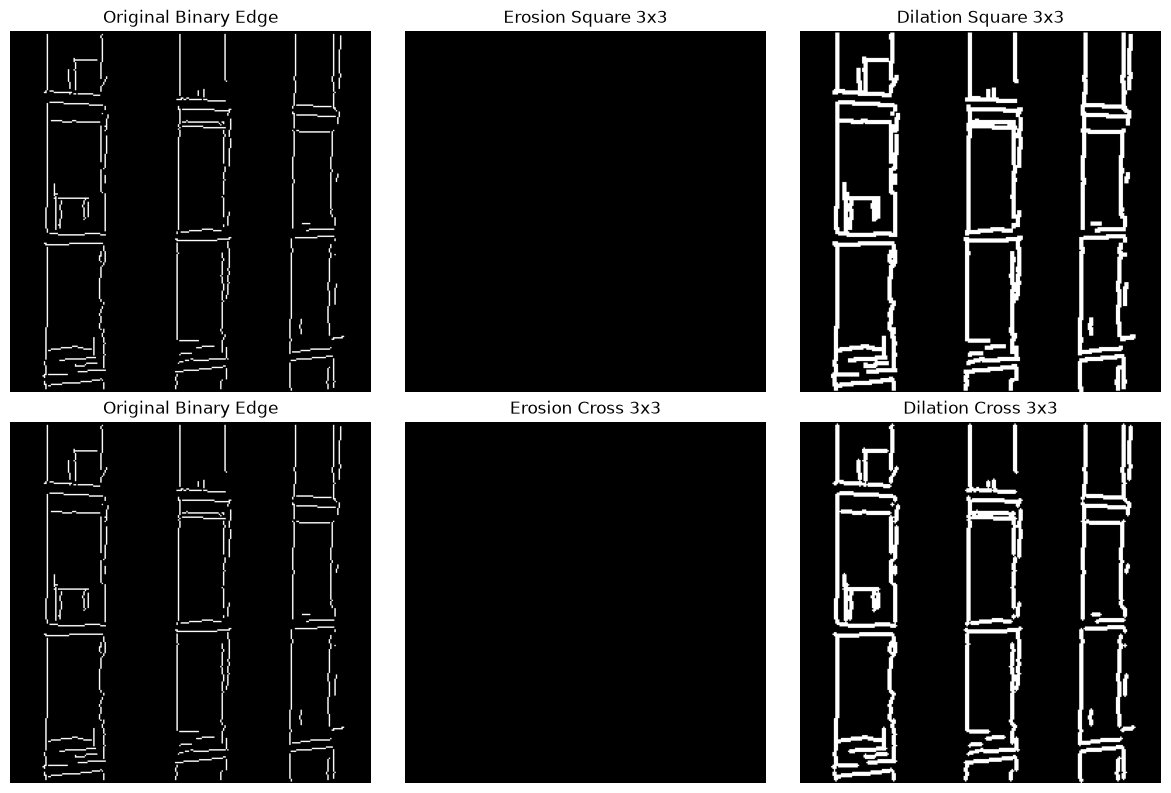

In [122]:
erosion_square = erosion(
    binary_edge_map,
    square_kernel
)

dilation_square = dilation(
    binary_edge_map,
    square_kernel
)

erosion_cross = erosion(
    binary_edge_map,
    cross_kernel
)

dilation_cross = dilation(
    binary_edge_map,
    cross_kernel
)

plt.figure(figsize=(12,8))

plt.subplot(2,3,1)
plt.imshow(binary_edge_map,cmap="gray")
plt.title("Original Binary Edge")
plt.axis("off")

plt.subplot(2,3,2)
plt.imshow(erosion_square,cmap="gray")
plt.title("Erosion Square 3x3")
plt.axis("off")

plt.subplot(2,3,3)
plt.imshow(dilation_square,cmap="gray")
plt.title("Dilation Square 3x3")
plt.axis("off")

plt.subplot(2,3,4)
plt.imshow(binary_edge_map,cmap="gray")
plt.title("Original Binary Edge")
plt.axis("off")

plt.subplot(2,3,5)
plt.imshow(erosion_cross,cmap="gray")
plt.title("Erosion Cross 3x3")
plt.axis("off")

plt.subplot(2,3,6)
plt.imshow(dilation_cross,cmap="gray")
plt.title("Dilation Cross 3x3")
plt.axis("off")

plt.tight_layout()
plt.show()

## Morphological Effects

- **Erosion:** shrinks foreground/edge regions and can remove small isolated pixels.
- **Dilation:** expands foreground/edge regions and can connect nearby gaps.
- **Opening:** erosion followed by dilation; useful for removing small noise.
- **Closing:** dilation followed by erosion; useful for filling small gaps and connecting nearby regions.


### Apply opening and closing

In [123]:
opening_result = dilation(
    erosion(
        binary_edge_map,
        square_kernel
    ),
    square_kernel
)
closing_result = erosion(
    dilation(
        binary_edge_map,
        square_kernel
    ),
    square_kernel
)

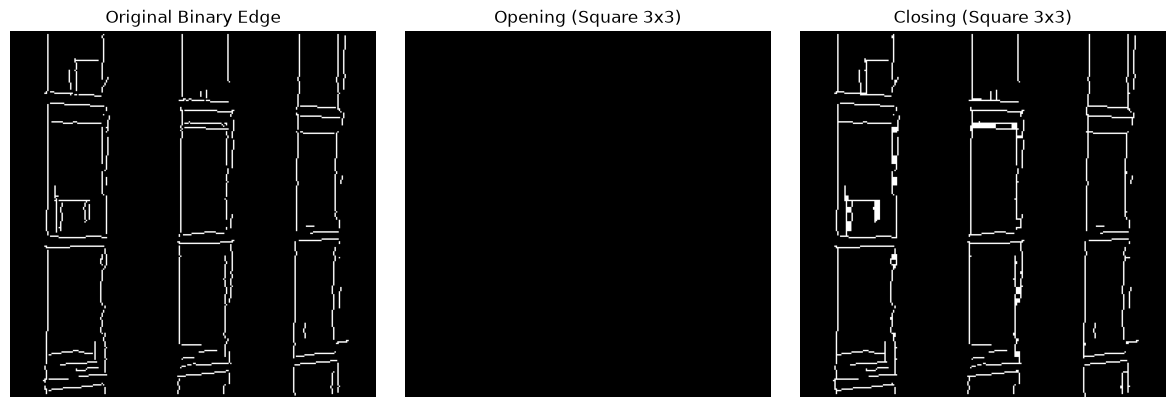

In [124]:
plt.figure(figsize=(12,4))


plt.subplot(1,3,1)

plt.imshow(
    binary_edge_map,
    cmap="gray"
)

plt.title("Original Binary Edge")

plt.axis("off")



plt.subplot(1,3,2)

plt.imshow(
    opening_result,
    cmap="gray"
)

plt.title("Opening (Square 3x3)")

plt.axis("off")



plt.subplot(1,3,3)

plt.imshow(
    closing_result,
    cmap="gray"
)

plt.title("Closing (Square 3x3)")

plt.axis("off")


plt.tight_layout()

plt.show()

# Task 4 — Global thresholding with Otsu’s method

Use the original grayscale image from Task 1 (not a noisy or denoised version).

### Compute the 256-bin histogram manually

In [125]:
def compute_histogram(image):

    histogram = [0] * 256

    h, w = image.shape


    for i in range(h):

        for j in range(w):

            pixel = image[i,j]

            histogram[pixel] += 1


    return histogram

### Compute Otsu’s threshold using between-class variance

In [126]:
def otsu_method(image):

    hist = compute_histogram(image)


    total_pixels = image.shape[0] * image.shape[1]


    total_intensity = 0


    for i in range(256):

        total_intensity += i * hist[i]



    max_variance = 0

    best_threshold = 0


    weight_background = 0

    sum_background = 0



    variance_values = []



    for t in range(256):


        weight_background += hist[t]


        if weight_background == 0:
            variance_values.append(0)
            continue



        weight_foreground = (
            total_pixels - weight_background
        )


        if weight_foreground == 0:
            break



        sum_background += t * hist[t]


        mean_background = (
            sum_background / weight_background
        )


        mean_foreground = (
            (total_intensity - sum_background)
            /
            weight_foreground
        )



        between_variance = (
            weight_background *
            weight_foreground *
            (mean_background - mean_foreground)**2
        )


        variance_values.append(
            between_variance
        )


        if between_variance > max_variance:

            max_variance = between_variance

            best_threshold = t



    return best_threshold, hist, variance_values

Otsu Threshold = 129


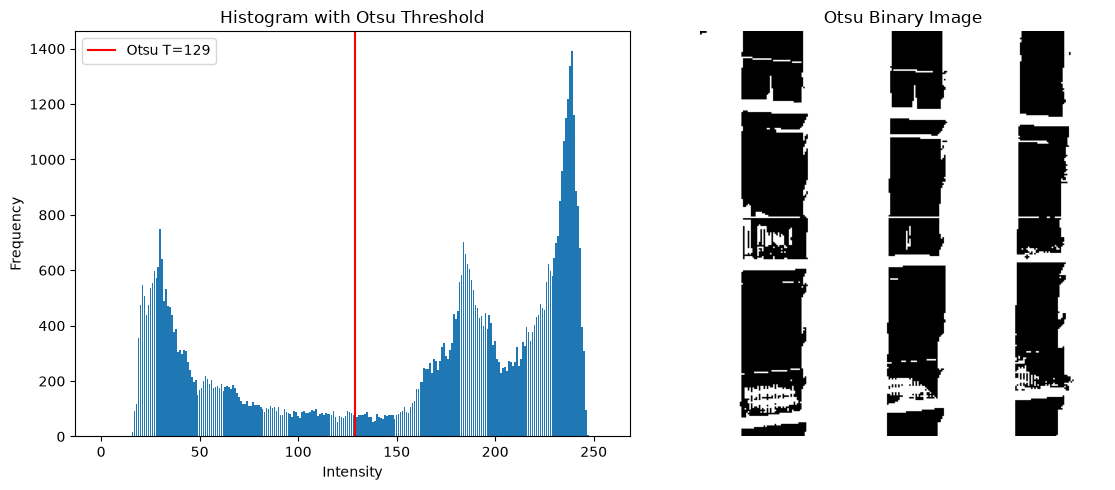

In [127]:
def binary_threshold(image, threshold):

    h,w = image.shape


    result = np.zeros(
        (h,w),
        dtype=np.uint8
    )


    for i in range(h):

        for j in range(w):

            if image[i,j] >= threshold:

                result[i,j] = 255


    return result

# Convert your existing grayimg list into a NumPy array
original_gray = np.array(grayimg, dtype=np.uint8)

otsu_T, histogram, variance = otsu_method(
    original_gray
)

otsu_binary = binary_threshold(
    original_gray,
    otsu_T
)

print("Otsu Threshold =", otsu_T)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.bar(
    range(256),
    histogram
)

plt.axvline(
    otsu_T,
    color="red",
    label=f"Otsu T={otsu_T}"
)

plt.title(
    "Histogram with Otsu Threshold"
)

plt.xlabel("Intensity")

plt.ylabel("Frequency")

plt.legend()

plt.subplot(1,2,2)

plt.imshow(
    otsu_binary,
    cmap="gray"
)

plt.title(
    "Otsu Binary Image"
)

plt.axis("off")

plt.tight_layout()

plt.show()